In [24]:
pip install pandas


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [26]:
df = pd.read_csv("movie.csv")
df.head()

,S.No,movie_id,popularity,movie_title,original_title,language,release_date,vote_avg,vote_count
0,0,569094,3911.157,Spider-Man: Across the Spider-Verse,Spider-Man: Across the Spider-Verse,en,31-05-2023,8.5,3328
1,1,667538,2593.944,Transformers: Rise of the Beasts,Transformers: Rise of the Beasts,en,06-06-2023,7.5,2718
2,2,298618,2344.392,The Flash,The Flash,en,13-06-2023,7.0,2286
3,3,346698,2120.771,Barbie,Barbie,en,19-07-2023,7.5,2977
4,4,1006462,1969.340,The Flood,The Flood,en,14-07-2023,6.9,110


In [27]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset shape: (10000, 9)

Column names:
['S.No', 'movie_id', 'popularity', 'movie_title', 'original_title', 'language', 'release_date', 'vote_avg', 'vote_count']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   S.No            10000 non-null  int64  
 1   movie_id        10000 non-null  int64  
 2   popularity      10000 non-null  float64
 3   movie_title     10000 non-null  object 
 4   original_title  10000 non-null  object 
 5   language        10000 non-null  object 
 6   release_date    9993 non-null   object 
 7   vote_avg        10000 non-null  float64
 8   vote_count      10000 non-null  int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 703.3+ KB

Statistical summary:


,S.No,movie_id,popularity,movie_title,original_title,language,release_date,vote_avg,vote_count
count,10000.00000,1.000000e+04,10000.000000,10000,10000,10000,9993,10000.000000,10000.000000
unique,NaN,NaN,NaN,9723,9723,49,6026,NaN,NaN
top,NaN,NaN,NaN,The Three Musketeers,The Three Musketeers,en,15-08-2023,NaN,NaN
freq,NaN,NaN,NaN,4,4,7195,67,NaN,NaN
mean,4999.50000,3.037054e+05,35.759293,NaN,NaN,NaN,NaN,6.340260,1571.614300
std,2886.89568,3.424062e+05,91.696996,NaN,NaN,NaN,NaN,1.414885,2922.856516
min,0.00000,5.000000e+00,13.969000,NaN,NaN,NaN,NaN,0.000000,0.000000
25%,2499.75000,1.157325e+04,16.731000,NaN,NaN,NaN,NaN,5.900000,141.000000
50%,4999.50000,1.219210e+05,21.345000,NaN,NaN,NaN,NaN,6.600000,510.500000
75%,7499.25000,5.395570e+05,32.324500,NaN,NaN,NaN,NaN,7.100000,1604.250000


In [28]:
df = df.drop_duplicates().copy()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (10000, 9)


In [29]:
if "release_date" in df.columns:
      df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

      numeric_cols = df.select_dtypes(include=np.number).columns
      for col in numeric_cols:
          df[col] = df[col].fillna(df[col].median())

          categorical_cols = df.select_dtypes(include=["object", "category"]).columns
          for col in categorical_cols:
              mode_values = df[col].mode()
if not mode_values.empty:
                          df[col] = df[col].fillna(mode_values[0])

                          print("Missing values after cleaning:")
                          print(df.isnull().sum())

Missing values after cleaning:
S.No               0
movie_id           0
popularity         0
movie_title        0
original_title     0
language           0
release_date      14
vote_avg           0
vote_count         0
dtype: int64


/tmp/ipykernel_1052/2858823206.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")


In [30]:
top_movies = df.sort_values("popularity", ascending=False).head(10)
display(top_movies[["movie_title", "popularity"]])

,movie_title,popularity
0,Spider-Man: Across the Spider-Verse,3911.157
1,Transformers: Rise of the Beasts,2593.944
2,The Flash,2344.392
3,Barbie,2120.771
4,The Flood,1969.340
5,Insidious: The Red Door,1906.145
6,Meg 2: The Trench,1847.433
7,Operacja: Soulcatcher,1770.520
8,Hidden Strike,1549.911
9,No Hard Feelings,1520.294


In [31]:
top_rated = (
      df[df["vote_count"] >= 100]
          .sort_values("vote_avg", ascending=False)
              .head(10)
              )
display(top_rated[["movie_title", "vote_avg", "vote_count"]])


,movie_title,vote_avg,vote_count
272,The Shawshank Redemption,8.7,24354
185,The Godfather,8.7,18431
872,Schindler's List,8.6,14408
2025,दिलवाले दुल्हनिया ले जायेंगे,8.6,4219
842,The Godfather Part II,8.6,11127
8861,Taylor Swift: The 1989 World Tour - Live,8.6,125
4044,Gabriel's Inferno,8.5,2353
561,七人の侍,8.5,3170
599,기생충,8.5,16194
427,千と千尋の神隠し,8.5,14713


In [32]:
language_count = df["language"].value_counts()
display(language_count.head(10))

,count
language,
en,7195
ja,712
ko,416
fr,323
es,299
it,163
zh,161
cn,156
ru,93


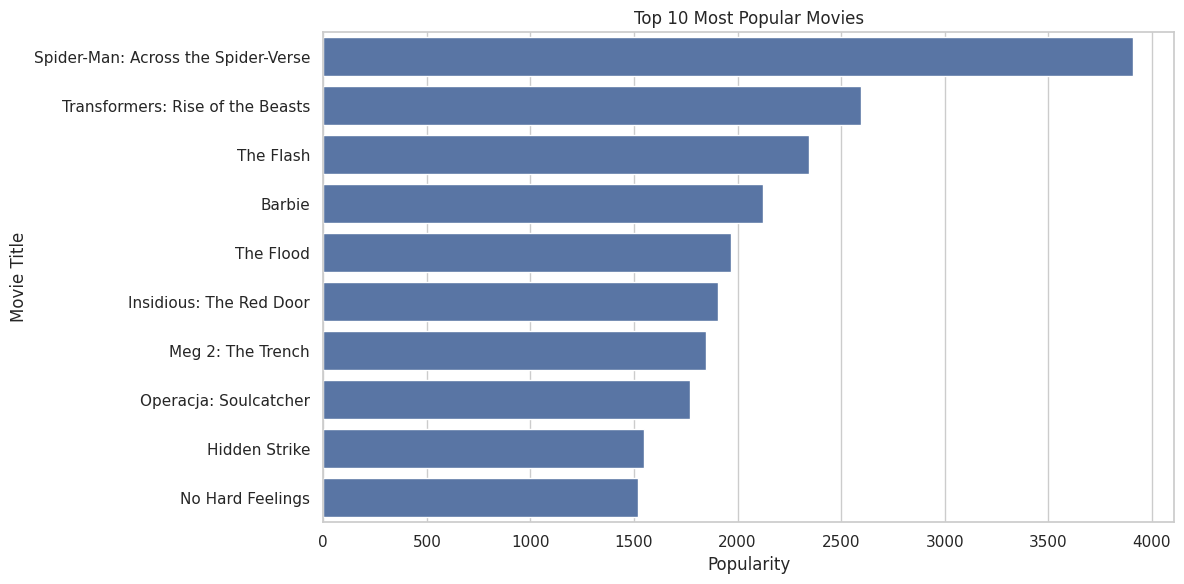

In [33]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_movies, x="popularity", y="movie_title")
plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

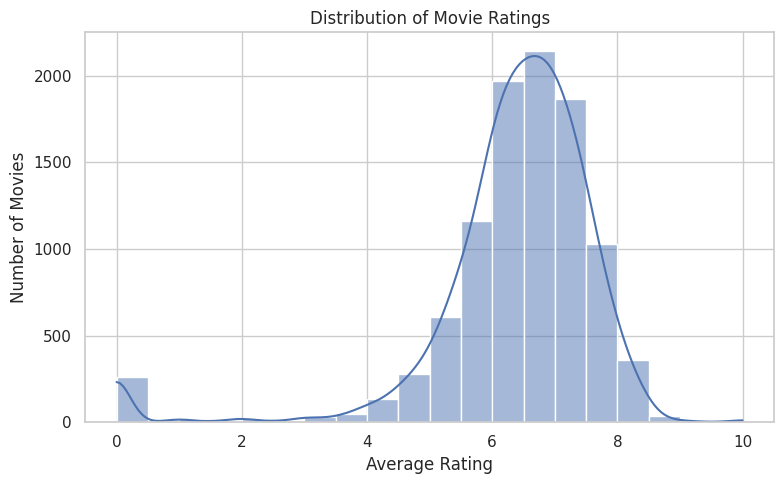

In [34]:
plt.figure(figsize=(8, 5))
sns.histplot(df["vote_avg"].dropna(), bins=20, kde=True)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

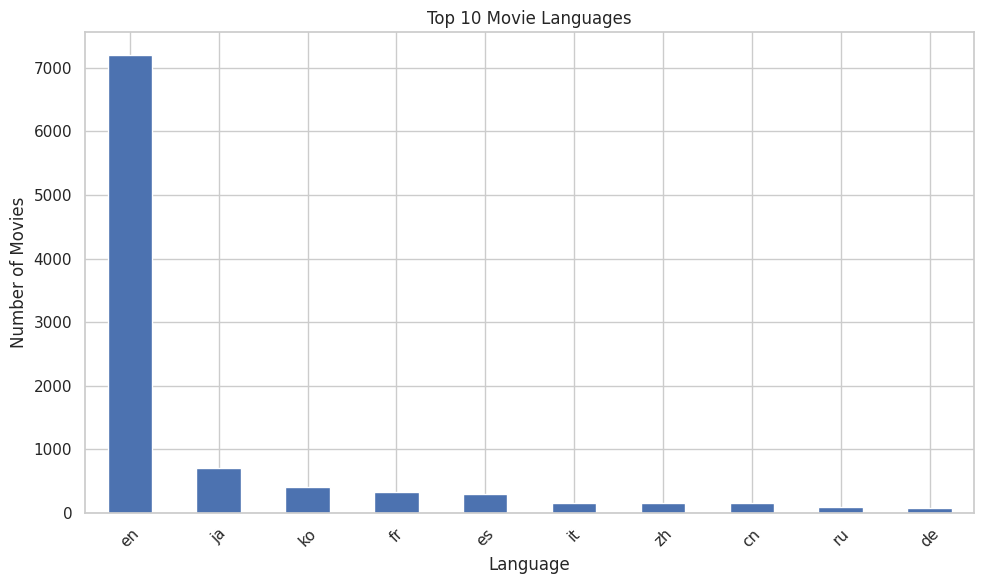

In [35]:
plt.figure(figsize=(10, 6))
language_count.head(10).plot(kind="bar")
plt.title("Top 10 Movie Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

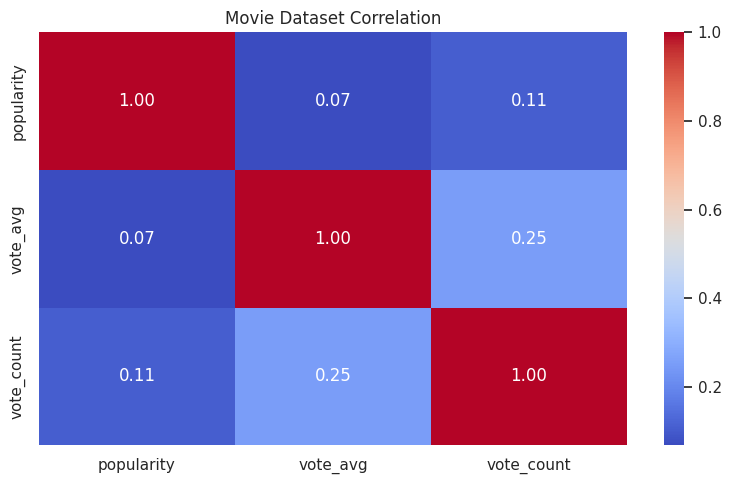

In [36]:
numeric_for_corr = df[["popularity", "vote_avg", "vote_count"]]
plt.figure(figsize=(8, 5))
sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Movie Dataset Correlation")
plt.tight_layout()
plt.show()

In [37]:
print("Total movies:", len(df))

Total movies: 10000


In [38]:
print("Average rating:", df["vote_avg"].mean())

Average rating: 6.34026


In [39]:
if not df["vote_count"].dropna().empty:
  most_voted = df.loc[df["vote_count"].idxmax()]
  print("Most voted movie:", most_voted["movie_title"])
  print("Vote count:", most_voted["vote_count"])
else:
  print("Vote count data is unavailable.")

Most voted movie: Inception
Vote count: 34241
